In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

BASE = Path(r"C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0")
DIRS = {"clean": BASE / "data" / "clean" / "biofarmaka",
        "model_ready": BASE / "data" / "model_ready",
        "eda": BASE / "outputs" / "eda",
        "reports": BASE / "outputs" / "reports"}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

clean = pd.read_csv(DIRS["clean"] / "biofarmaka_kecamatan_clean.csv", encoding="utf-8-sig")
kab = pd.read_csv(DIRS["clean"] / "biofarmaka_kabupaten_clean.csv", encoding="utf-8-sig")
COMPLETE_YEARS = sorted(clean.loc[clean["tahun_lengkap"], "tahun"].unique().tolist())
print("Tahun lengkap:", COMPLETE_YEARS, "| kecamatan:", clean.shape, "| kabupaten:", kab.shape)

Tahun lengkap: [2020, 2021, 2022, 2023, 2024] | kecamatan: (2496, 19) | kabupaten: (96, 8)


F1 — Siapkan seri waktu dan metode

In [2]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
warnings.filterwarnings("ignore")
years = sorted(COMPLETE_YEARS)                      
H = 2                                              
fallback = {"n": 0}                                

def f_naive(y, h):  return np.repeat(y[-1], h)
def f_linear(y, h): return np.polyval(np.polyfit(np.arange(len(y)), y, 1), np.arange(len(y), len(y) + h))
def f_ets(y, h):
    try:    return SimpleExpSmoothing(y, initialization_method="estimated").fit().forecast(h)
    except Exception: fallback["n"] += 1; return f_naive(y, h)
def f_ets_trend(y, h):
    try:    return ExponentialSmoothing(y, trend="add", damped_trend=True, initialization_method="estimated").fit().forecast(h)
    except Exception: fallback["n"] += 1; return f_naive(y, h)
METHODS = {"naive (tahun lalu)": f_naive, "ETS sederhana": f_ets, "ETS tren teredam": f_ets_trend, "regresi linear": f_linear}
FORECAST_METHOD = "ETS sederhana"                   # model utama

def build_series(df, keys, value):
    p = df[df["tahun"].isin(years)].pivot(index=keys, columns="tahun", values=value)[years]
    return p[(p.notna().all(axis=1)) & (p > 0).all(axis=1)]          # hanya seri lengkap dan positif
SERIES = {}
for target in ["produksi", "luas"]:
    SERIES[("kabupaten", target)] = build_series(kab, "komoditas", target)
    SERIES[("kecamatan", target)] = build_series(clean, ["kecamatan", "komoditas"], target)
for k, v in SERIES.items():
    total = clean.groupby(["kecamatan", "komoditas"]).ngroups if k[0] == "kecamatan" else kab["komoditas"].nunique()
    print(f"Seri {k[0]:9s} | {k[1]:8s}: dipakai {len(v)} dari {total}")

Seri kabupaten | produksi: dipakai 16 dari 16
Seri kecamatan | produksi: dipakai 348 dari 416
Seri kabupaten | luas    : dipakai 11 dari 16
Seri kecamatan | luas    : dipakai 342 dari 416


F2 — Backtest (latih hanya data sebelum tahun uji, tanpa data masa depan)

Seri yang gagal di-fit dan memakai cadangan naive: 0


model               ETS sederhana  ETS tren teredam  naive (tahun lalu)  regresi linear
level     target                                                                       
kabupaten luas               8.73              7.86                5.54            7.71
          produksi          10.85             13.35               11.71           11.82
kecamatan luas               7.37              8.80                7.28            8.63
          produksi           6.89              8.38                6.46            8.44

kabupaten | luas     -> terbaik: naive (tahun lalu) (5.54%) | ETS sederhana: 8.73% | naive: 5.54%
kabupaten | produksi -> terbaik: ETS sederhana (10.85%) | ETS sederhana: 10.85% | naive: 11.71%
kecamatan | luas     -> terbaik: naive (tahun lalu) (7.28%) | ETS sederhana: 7.37% | naive: 7.28%
kecamatan | produksi -> terbaik: naive (tahun lalu) (6.46%) | ETS sederhana: 6.89% | naive: 6.46%


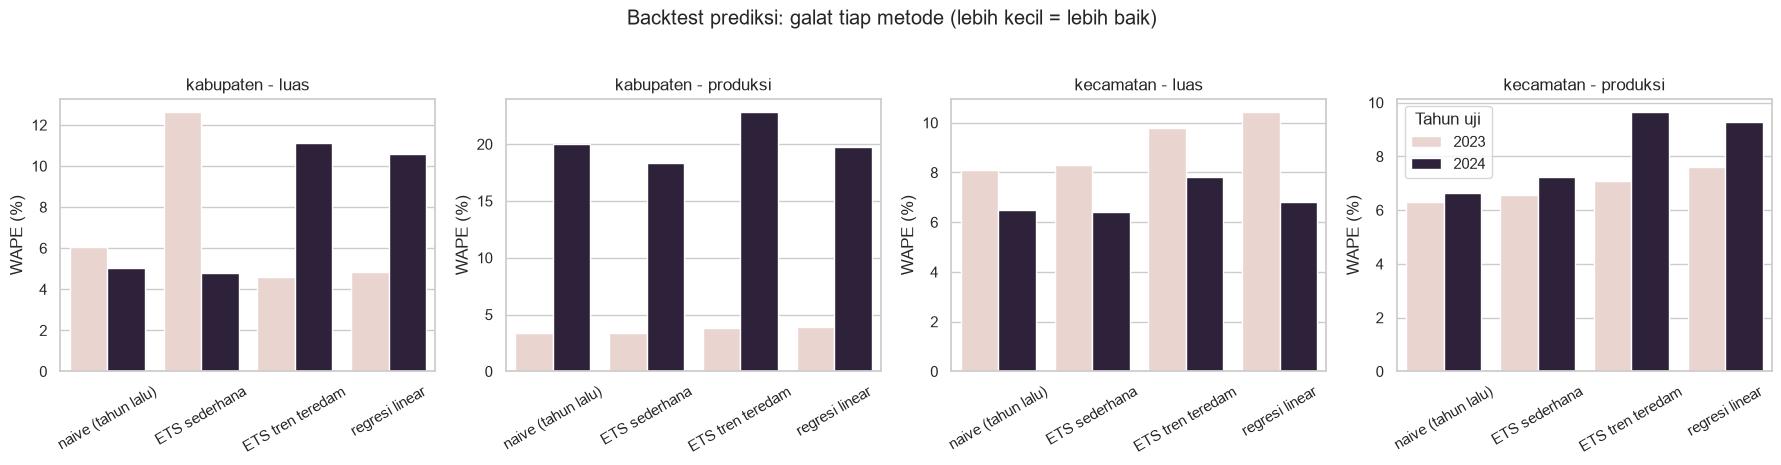

In [4]:
rows = []
for (level, target), P in SERIES.items():
    for origin in range(3, len(years)):               # latih tahun [0:origin], uji tahun ke-origin
        actual = P[years[origin]].values
        for mname, fn in METHODS.items():
            pred = np.clip(np.array([fn(r[:origin].astype(float), 1)[0] for r in P[years[:origin]].values]), 0, None)
            rows.append({"level": level, "target": target, "uji_tahun": years[origin], "n_latih_tahun": origin, "model": mname,
                         "n_seri": len(P), "MAE": np.abs(actual - pred).mean(),
                         "WAPE_%": 100 * np.abs(actual - pred).sum() / actual.sum(),
                         "MdAPE_%": 100 * np.median(np.abs(actual - pred) / actual)})
bt = pd.DataFrame(rows).round(3)
bt.to_csv(DIRS["reports"] / "backtest_forecast_biofarmaka.csv", index=False)
print("Seri yang gagal di-fit dan memakai cadangan naive:", fallback["n"])
summary = bt.groupby(["level", "target", "model"])["WAPE_%"].mean().round(2).unstack("model")
display(summary)
for (level, target), r in summary.iterrows():
    print(f"{level:9s} | {target:8s} -> terbaik: {r.idxmin()} ({r.min():.2f}%) | {FORECAST_METHOD}: {r[FORECAST_METHOD]:.2f}% | naive: {r['naive (tahun lalu)']:.2f}%")

fig, ax = plt.subplots(1, 4, figsize=(18, 4.5), sharey=False)
for a, ((level, target), g) in zip(ax, bt.groupby(["level", "target"])):
    sns.barplot(data=g, x="model", y="WAPE_%", hue="uji_tahun", ax=a)
    a.set_title(f"{level} - {target}"); a.set_xlabel(""); a.set_ylabel("WAPE (%)"); a.tick_params(axis="x", rotation=30)
    if a is not ax[-1]: a.get_legend().remove()
ax[-1].legend(title="Tahun uji"); fig.suptitle("Backtest prediksi: galat tiap metode (lebih kecil = lebih baik)", y=1.03)
plt.tight_layout(); plt.show()

F3 — Prediksi 2025–2026 dan grafik

Prediksi tersimpan: (1434, 10)


tahun,2025,2026
komoditas,,
jahe,286925.0,286925.0
jeruk_nipis,688812.0,688812.0
kapulaga,125489.0,125489.0
keji_beling,3988.0,3988.0
kencur,45716.0,45716.0
kunyit,13275648.0,13275648.0
laos,36213.0,36213.0
lempuyang,3769.0,3769.0
lidah_buaya,103032.0,103032.0


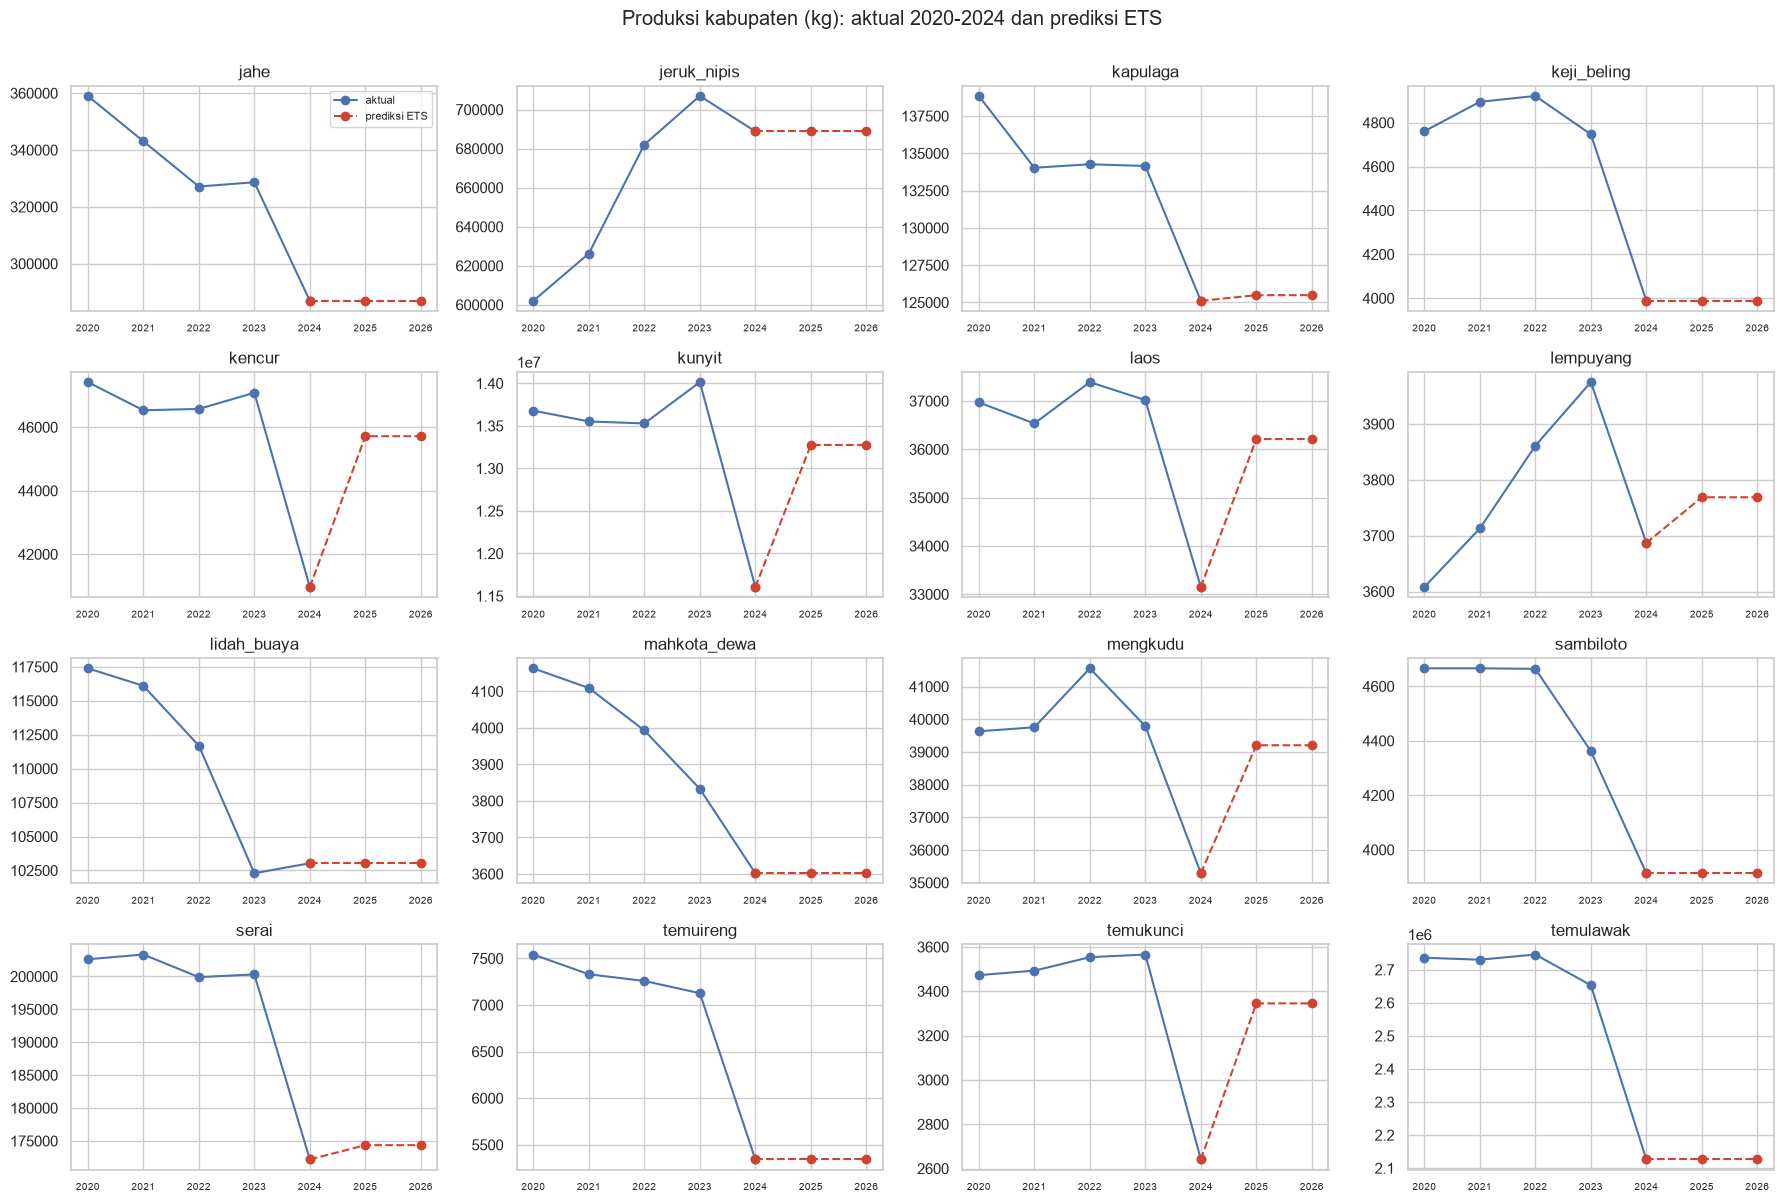

In [5]:
fc_rows = []
for (level, target), P in SERIES.items():
    wape = summary.loc[(level, target), FORECAST_METHOD]
    for idx, r in P.iterrows():
        y = r.values.astype(float); f = np.clip(METHODS[FORECAST_METHOD](y, H), 0, None)
        keys = {"komoditas": idx} if level == "kabupaten" else {"kecamatan": idx[0], "komoditas": idx[1]}
        for i in range(H):
            fc_rows.append({"level": level, "target": target, **keys, "tahun": years[-1] + 1 + i, "prediksi": f[i],
                            "aktual_terakhir": y[-1], "perubahan_vs_terakhir_%": 100 * (f[i] / y[-1] - 1), "galat_backtest_WAPE_%": wape})
fc = pd.DataFrame(fc_rows)
unit_map = kab.drop_duplicates("komoditas").set_index("komoditas")["unit_luas"]
fc["unit"] = np.where(fc["target"] == "produksi", "kg", fc["komoditas"].map(unit_map))
fc.round(3).to_csv(DIRS["model_ready"] / "prediksi_ets_biofarmaka.csv", index=False)
print("Prediksi tersimpan:", fc.shape)
display(fc[(fc.level == "kabupaten") & (fc.target == "produksi")].pivot(index="komoditas", columns="tahun", values="prediksi").round(0))

hist = SERIES[("kabupaten", "produksi")]; fcp = fc[(fc.level == "kabupaten") & (fc.target == "produksi")]
fig, axes = plt.subplots(4, 4, figsize=(18, 12))
for a, kom in zip(axes.ravel(), hist.index):
    a.plot(years, hist.loc[kom].values, "o-", label="aktual"); f = fcp[fcp.komoditas == kom]
    a.plot([years[-1]] + f["tahun"].tolist(), [hist.loc[kom].values[-1]] + f["prediksi"].tolist(), "o--", c="#d1432f", label="prediksi ETS")
    a.set_title(kom); a.set_xticks(years + f["tahun"].tolist()); a.tick_params(axis="x", labelsize=7)
for a in axes.ravel()[len(hist):]: a.axis("off")
axes[0, 0].legend(fontsize=8); fig.suptitle("Produksi kabupaten (kg): aktual 2020-2024 dan prediksi ETS", y=1.0)
plt.tight_layout(); plt.show()

C1 — Evaluasi jumlah klaster

Profil klaster: (26, 16) (kecamatan x komoditas, rata-rata produksi kg/tahun 2020-2024)


,metode,k,silhouette,davies_bouldin,klaster_terkecil,ukuran
0,KMeans,2,0.391,1.331,3,"[23, 3]"
1,Agglomerative,2,0.391,1.331,3,"[3, 23]"
2,KMeans,3,0.354,0.895,1,"[1, 23, 2]"
3,Agglomerative,3,0.354,0.895,1,"[23, 2, 1]"
4,KMeans,4,0.120,1.389,1,"[16, 7, 1, 2]"
5,Agglomerative,4,0.193,1.037,1,"[20, 2, 1, 3]"
6,KMeans,5,0.128,1.376,1,"[2, 7, 13, 3, 1]"
7,Agglomerative,5,0.120,1.433,1,"[2, 13, 1, 3, 7]"
8,KMeans,6,0.126,1.092,1,"[1, 13, 7, 1, 3, 1]"
9,Agglomerative,6,0.117,1.141,1,"[13, 7, 1, 3, 1, 1]"


K dipilih = 2


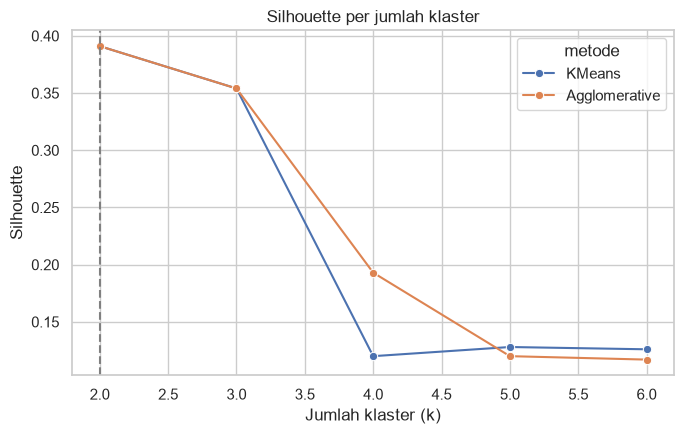

In [9]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # hilangkan peringatan joblib di Windows; ganti sesuai jumlah core

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

prof = (clean[clean["tahun"].isin(years)].pivot_table(index="kecamatan", columns="komoditas", values="produksi", aggfunc="mean")
        .fillna(0))                                  # tidak ada laporan produksi = 0 HANYA untuk profil klaster
X = StandardScaler().fit_transform(np.log1p(prof))   # log (skala antarkomoditas beda jauh) lalu standardisasi
print("Profil klaster:", prof.shape, "(kecamatan x komoditas, rata-rata produksi kg/tahun 2020-2024)")

rows = []
for k in range(2, 7):
    for name, lab in [("KMeans", KMeans(k, n_init=50, random_state=42).fit_predict(X)),
                      ("Agglomerative", AgglomerativeClustering(k, linkage="ward").fit_predict(X))]:
        rows.append({"metode": name, "k": k, "silhouette": silhouette_score(X, lab), "davies_bouldin": davies_bouldin_score(X, lab),
                     "klaster_terkecil": np.bincount(lab).min(), "ukuran": np.bincount(lab).tolist()})
ev = pd.DataFrame(rows).round(3); display(ev)
ev.to_csv(DIRS["reports"] / "evaluasi_klaster_biofarmaka.csv", index=False)

K_OVERRIDE = None                                    
ok = ev[(ev["metode"] == "KMeans") & (ev["klaster_terkecil"] >= 2)]
K_FINAL = K_OVERRIDE or int(ok.sort_values("silhouette", ascending=False).iloc[0]["k"])
print(f"K dipilih = {K_FINAL}")

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.lineplot(data=ev, x="k", y="silhouette", hue="metode", marker="o", ax=ax)
ax.axvline(K_FINAL, ls="--", c="gray")
ax.set_title("Silhouette per jumlah klaster"); ax.set_xlabel("Jumlah klaster (k)"); ax.set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

C2 — Klaster akhir, profil, dan grafik

Kesepakatan KMeans vs Agglomerative (ARI, 1 = identik): 1.0


,jumlah,produksi_rata2,porsi_total,anggota
klaster,,,,
1,23,788080.0,99.4,"Banyakan, Grogol, Puncu, Pare, Kandat, Gampeng..."
2,3,37937.8,0.6,"Gurah, Plemahan, Papar"


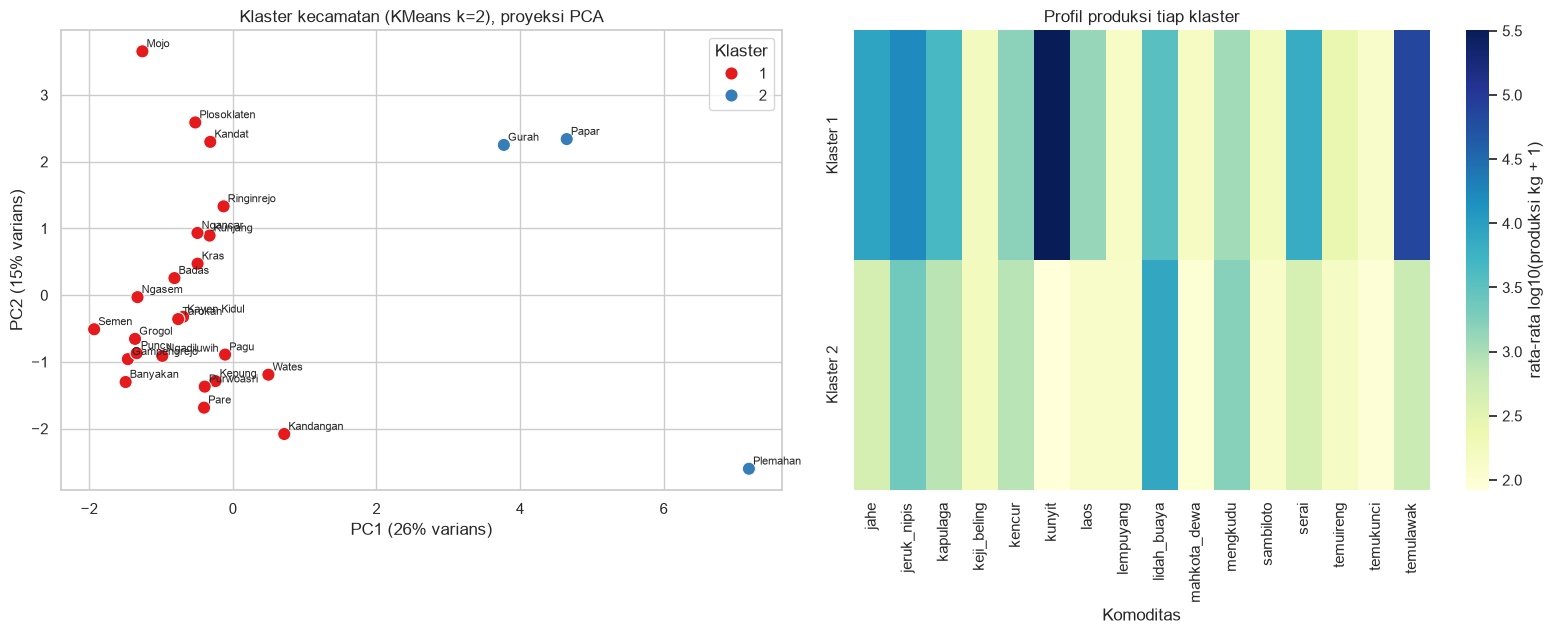

In [10]:
km = KMeans(K_FINAL, n_init=50, random_state=42).fit(X); ag = AgglomerativeClustering(K_FINAL, linkage="ward").fit(X)
total = prof.sum(axis=1)
res_cl = pd.DataFrame({"kecamatan": prof.index, "klaster_kmeans": km.labels_, "klaster_agglo": ag.labels_,
                       "produksi_rata2_kg_per_tahun": total.values, "porsi_kabupaten_%": 100 * total.values / total.sum()})
order = res_cl.groupby("klaster_kmeans")["produksi_rata2_kg_per_tahun"].mean().sort_values(ascending=False).index
rank = {c: i + 1 for i, c in enumerate(order)}; res_cl["klaster"] = res_cl["klaster_kmeans"].map(rank)    # 1 = produksi tertinggi
res_cl["top3_komoditas"] = [", ".join(prof.loc[k].sort_values(ascending=False).index[:3]) for k in res_cl["kecamatan"]]
res_cl = res_cl.sort_values(["klaster", "produksi_rata2_kg_per_tahun"], ascending=[True, False]).round(2)
res_cl.to_csv(DIRS["reports"] / "klaster_kecamatan_biofarmaka.csv", index=False)
print("Kesepakatan KMeans vs Agglomerative (ARI, 1 = identik):", round(adjusted_rand_score(km.labels_, ag.labels_), 3))
display(res_cl.groupby("klaster").agg(jumlah=("kecamatan", "size"), produksi_rata2=("produksi_rata2_kg_per_tahun", "mean"),
                                      porsi_total=("porsi_kabupaten_%", "sum"), anggota=("kecamatan", lambda s: ", ".join(s))).round(1))

pca = PCA(2, random_state=42).fit(X); Z = pca.transform(X); lab_rank = pd.Series(km.labels_).map(rank).values
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=lab_rank, palette="Set1", s=90, ax=ax[0])
for (x_, y_), n in zip(Z, prof.index): ax[0].annotate(n, (x_, y_), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax[0].set_title(f"Klaster kecamatan (KMeans k={K_FINAL}), proyeksi PCA"); ax[0].set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.0f}% varians)")
ax[0].set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.0f}% varians)"); ax[0].legend(title="Klaster")
cp = np.log10(prof + 1).groupby(lab_rank).mean(); cp.index = [f"Klaster {i}" for i in cp.index]
sns.heatmap(cp, cmap="YlGnBu", ax=ax[1], cbar_kws={"label": "rata-rata log10(produksi kg + 1)"}); ax[1].set_title("Profil produksi tiap klaster"); ax[1].set_xlabel("Komoditas")
plt.tight_layout(); plt.show()